<center><h1>Le_Casey_HW6</h1></center>

Name: Casey Le
<br>
Github Username: parakeet89
<br>
USC ID: 8489799178

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

import xgboost as xgb
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
df_train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, na_values='na')
df_test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, na_values='na')

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

| Technique | Description | sklearn |
|---|---|---|
| Mean imputation | Replace missing values with the feature mean | `SimpleImputer(strategy="mean")` |
| Median imputation | Replace missing values with the feature median | `SimpleImputer(strategy="median")` |
| Mode imputation | Replace missing values with the most frequent value | `SimpleImputer(strategy="most_frequent")` |
| KNN imputation | Use similar observations to estimate missing values | `KNNImputer` |
| Regression imputation | Predict missing values using multiple features | `IterativeImputer` |
| Multiple imputation | Generate multiple imputed datasets to account for uncertainty | `IterativeImputer` (MICE) |

For this dataset we will impute missing values with the mean for that column using the `SimpleImputer` by `sklearn` with the `strategy='mean'`. We will apply this approach for every numerical column with missing values.

In [3]:
num_cols_df_train = df_train.select_dtypes(include=["number"]).columns
num_imputer = SimpleImputer(strategy="mean")
df_train_imputed_num = pd.DataFrame(num_imputer.fit_transform(df_train[num_cols_df_train]), columns=num_cols_df_train)

In [4]:
# check to see if there are missing values in our target column
cat_cols_df_train = df_train.select_dtypes(exclude=["number"]).columns
df_train['class'].isnull().sum()

np.int64(0)

Our only column that isn't a numerical column is the `class` column, which doesn't contain any missing values. Thus we won't be needing to apply any imputation on this column.

We will now apply what we did to `df_train` to `df_test`.

In [5]:
num_cols_df_test = df_test.select_dtypes(include=["number"]).columns
df_test_imputed_num = pd.DataFrame(num_imputer.transform(df_test[num_cols_df_test]), columns=num_cols_df_test)

In [6]:
# check to see if there are missing values in our target column
cat_cols_df_test = df_test.select_dtypes(exclude=["number"]).columns
df_test['class'].isnull().sum()

np.int64(0)

#### (ii) Calculate the coefficient of variation

In [7]:
dict_train_cv = {}

for column in num_cols_df_train:
    m = df_train_imputed_num[column].mean()
    s = df_train_imputed_num[column].std()
    cv = s / m
    dict_train_cv[column] = float(cv)

#### (iii) Plot a correlation matrix

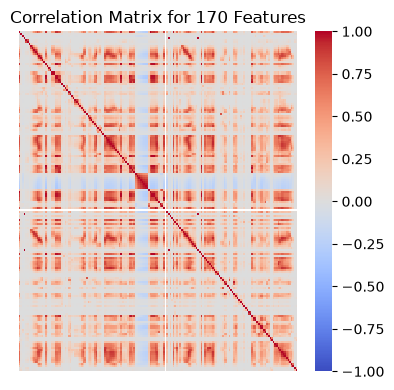

In [8]:
plt.figure(figsize=(4, 4))
sns.heatmap(df_train_imputed_num[num_cols_df_train].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Correlation Matrix for 170 Features')
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

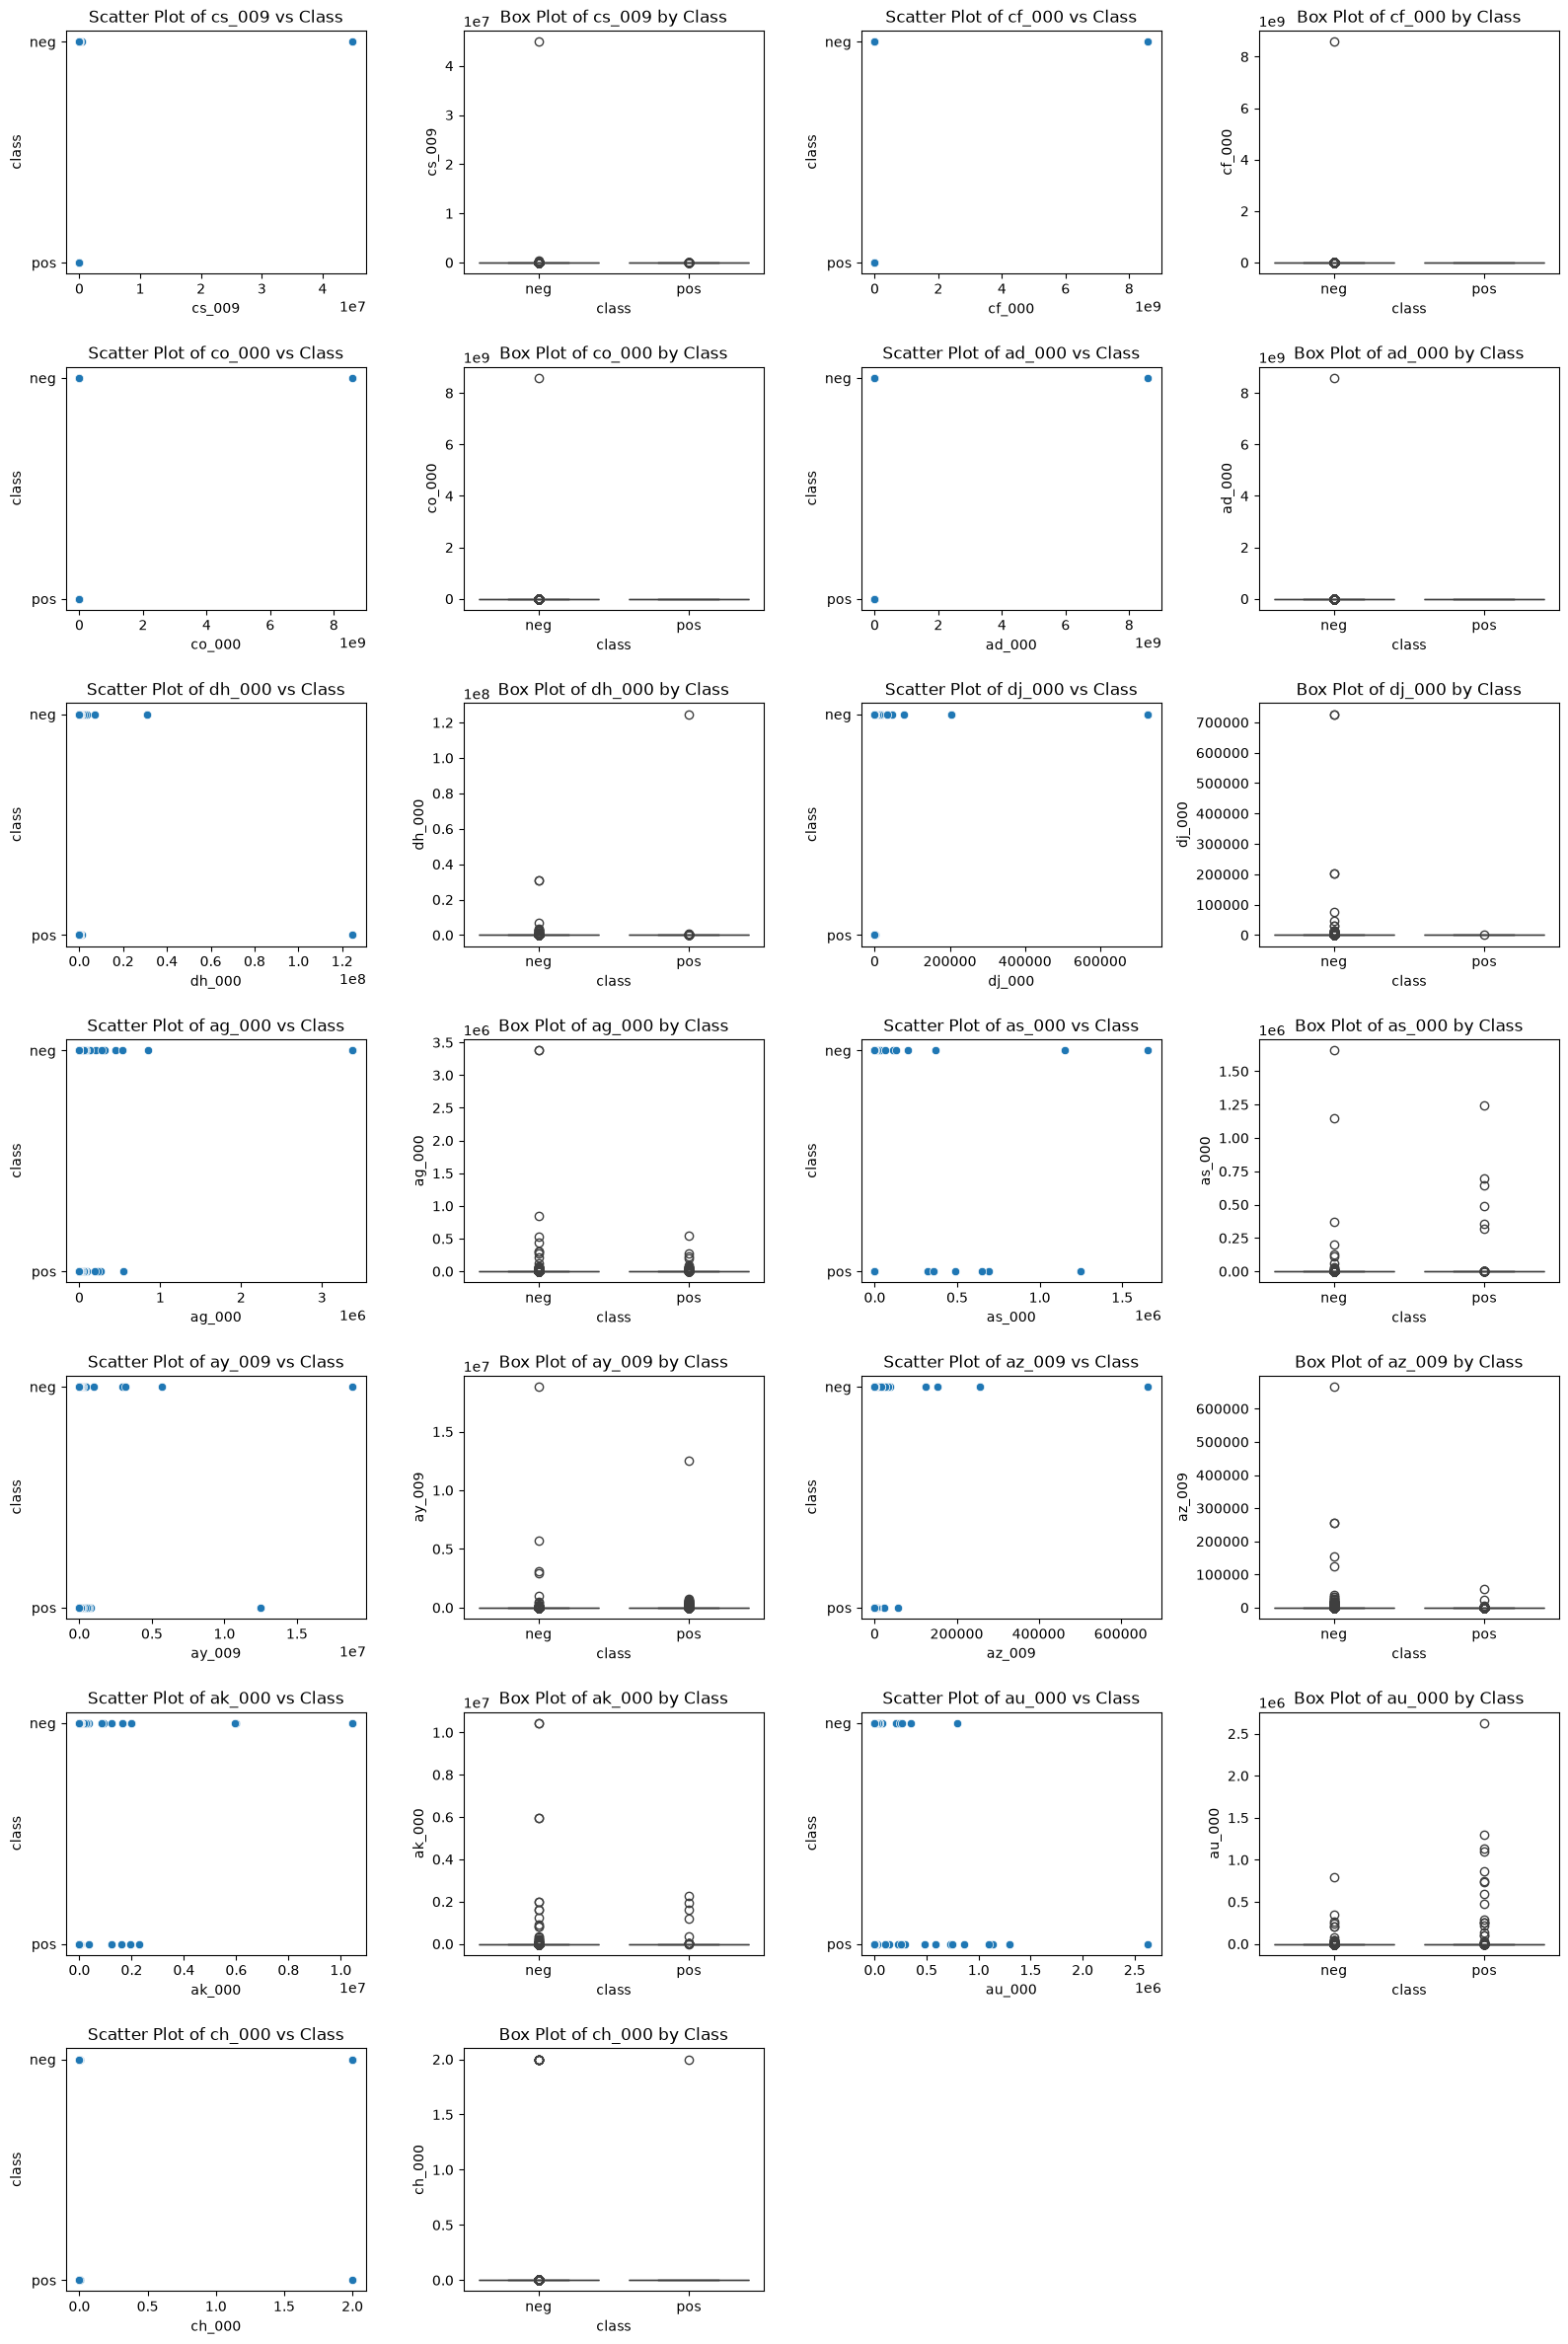

In [9]:
top_13_features = sorted(dict_train_cv, key=dict_train_cv.get, reverse=True)[:13]
plt.figure(figsize=(16, 24))
for feature in top_13_features:
    i = top_13_features.index(feature)

    plt.subplot(7, 4, 2*i+1)
    sns.scatterplot(x=df_train_imputed_num[feature], y=df_train['class'])
    plt.title(f'Scatter Plot of {feature} vs Class')

    plt.subplot(7, 4, 2*i+2)
    sns.boxplot(x=df_train['class'], y=df_train_imputed_num[feature])
    plt.title(f'Box Plot of {feature} by Class')

plt.tight_layout()
plt.show()

**Can you draw conclusions about significance of those features, just by the scatter plots?** Based on the scatterplots and boxplots of each of the top 13 features vs. our target variable `class`, we can't establish statistical significance of those features from the plots alone. The scatterplots show a lot of overlap between the two classes (neg and pos) for each feature, indicating that there is no clear separation between the classes based on these features individually. The boxplots also show extreme outliers, making it difficult to compare the distributions of the two classes. This suggests that features with a high coefficient of variation CV may not necessarily be strong predictors of the target variable `class`.

#### (v) Is this data set imbalanced?

In [10]:
pos_count = len(df_train[df_train['class'] == 'pos'])
neg_count = len(df_train) - pos_count
print(f"Number of positive observations: {pos_count}")
print(f"Number of negative observations: {neg_count}")

Number of positive observations: 1000
Number of negative observations: 59000


In [11]:
pos_rate = pos_count/(pos_count + neg_count)
pos_rate

0.016666666666666666

**Determine the number of positive and negative data. Is this data set imbalanced?** Yes, this dataset is imbalanced. There are 1000 positive observations compared to 59,000 negative observations, meaning that only 1.67% of the observations are `positive`.


### (c) Train a random forest

In [12]:
X_train = df_train_imputed_num
y_train = df_train['class']
X_test = df_test_imputed_num
y_test = df_test['class']

clf = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)
clf.fit(X_train, y_train)
y_pred_train = clf.predict(X_train)
y_pred = clf.predict(X_test)

#### 1(c)i Train

In [13]:
cm_train = confusion_matrix(y_train, y_pred_train)
cm_df_train = pd.DataFrame(cm_train, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
cm_df_train

,pred_neg,pred_pos
actual_neg,59000,0
actual_pos,1,999


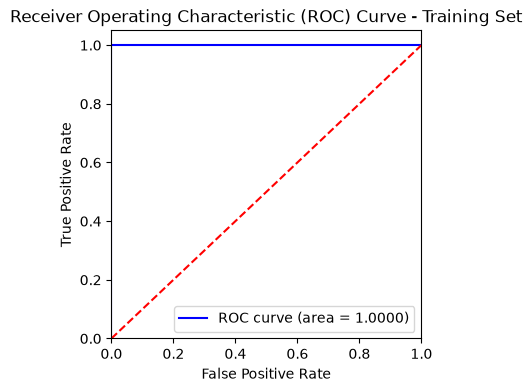

In [14]:
y_prob_train = clf.predict_proba(X_train)[:, 1]
fpr, tpr, thresholds = roc_curve(y_train, y_prob_train, pos_label='pos')

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_train, y_prob_train))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Training Set')
plt.legend(loc="lower right")
plt.show()

In [15]:
roc_auc = roc_auc_score(y_train, y_prob_train)
print(f"AUC (Area Under the ROC Curve) Score (Training Set): {roc_auc:.4f}")

AUC (Area Under the ROC Curve) Score (Training Set): 1.0000


In [16]:
train_error = (1 - accuracy_score(y_train, clf.predict(X_train))) * 100
print(f"Training Misclassification Error: {train_error:.4f}%")

Training Misclassification Error: 0.0017%


#### 1(c)ii Test

In [17]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
cm_df

,pred_neg,pred_pos
actual_neg,15609,16
actual_pos,107,268


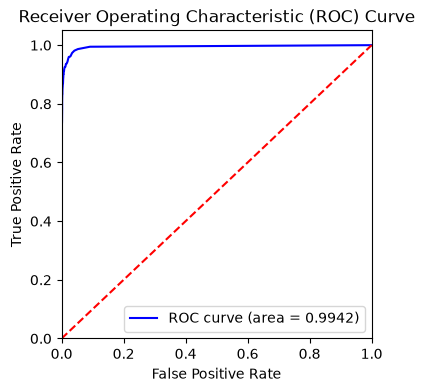

In [18]:
y_prob = clf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label='pos')

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_test, y_prob))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [19]:
roc_auc_test = roc_auc_score(y_test, y_prob)
print(f"AUC (Area Under the ROC Curve) Score: {roc_auc_test:.4f}")

AUC (Area Under the ROC Curve) Score: 0.9942


In [20]:
test_error = (1 - accuracy_score(y_test, clf.predict(X_test))) * 100
print(f"Test Misclassification Error: {test_error:.4f}%")

Test Misclassification Error: 0.7687%


In [21]:
oob_error = (1 - clf.oob_score_) * 100
print(f"Out of Bag Error Estimate: {oob_error:.4f}%")

Out of Bag Error Estimate: 0.6050%


The OOB error estimate (0.6050%) is a little lower than the test misclassification error (0.7687%), by 0.1637 percentage points, so the OOB estimate is a close estimate of the model's test error.

### (d) Research class imbalance in random forest

In [22]:
clf_balanced = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42, oob_score=True)
clf_balanced.fit(X_train, y_train)
y_pred_balanced_train = clf_balanced.predict(X_train)
y_pred_balanced = clf_balanced.predict(X_test)

/opt/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


#### 1(d)i Train

In [23]:
cm_balanced_train = confusion_matrix(y_train, y_pred_balanced_train)
cm_balanced_df_train = pd.DataFrame(cm_balanced_train, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for Balanced Random Forest (Training):")
cm_balanced_df_train

Confusion Matrix for Balanced Random Forest (Training):


,pred_neg,pred_pos
actual_neg,58985,15
actual_pos,0,1000


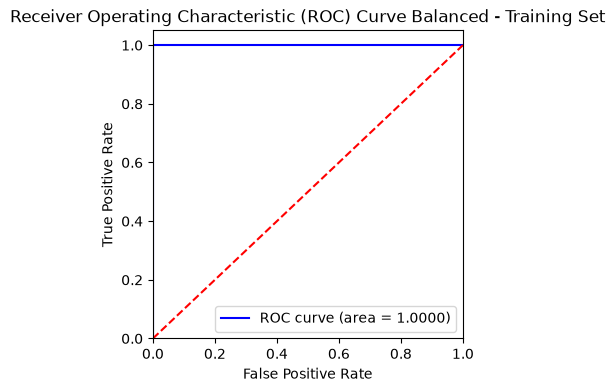

In [24]:
y_prob_train_balanced = clf_balanced.predict_proba(X_train)[:, 1]
fpr, tpr, thresholds = roc_curve(y_train, y_prob_train_balanced, pos_label='pos')

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_train, y_prob_train_balanced))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve Balanced - Training Set')
plt.legend(loc="lower right")
plt.show()

In [25]:
roc_auc_balanced = roc_auc_score(y_train, y_prob_train_balanced)
print(f"AUC (Area Under the ROC Curve) Score (Training Set): {roc_auc_balanced:.4f}")

AUC (Area Under the ROC Curve) Score (Training Set): 1.0000


In [26]:
train_error_balanced = (1 - accuracy_score(y_train, clf_balanced.predict(X_train))) * 100
print(f"Training Misclassification Error: {train_error_balanced:.4f}%")

Training Misclassification Error: 0.0250%


#### 1(d)ii Test

In [27]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)
cm_balanced_df = pd.DataFrame(cm_balanced, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for Balanced Random Forest:")
cm_balanced_df

Confusion Matrix for Balanced Random Forest:


,pred_neg,pred_pos
actual_neg,15572,53
actual_pos,94,281


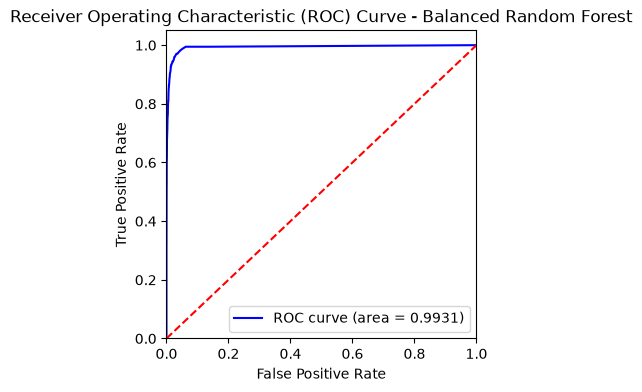

In [28]:
y_prob_balanced = clf_balanced.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob_balanced, pos_label='pos')

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_test, y_prob_balanced))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Balanced Random Forest')
plt.legend(loc="lower right")
plt.show()

In [29]:
roc_auc_score(y_test, y_prob_balanced)
print(f"AUC Score (balanced random forest): {roc_auc_score(y_test, y_prob_balanced):.4f}")

AUC Score (balanced random forest): 0.9931


In [30]:
test_error_balanced = (1 - accuracy_score(y_test, clf_balanced.predict(X_test))) * 100
print(f"Test Misclassification Error (balanced random forest): {test_error_balanced:.4f}%")

Test Misclassification Error (balanced random forest): 0.9188%


In [31]:
oob_error_balanced = (1 - clf_balanced.oob_score_) * 100
print(f"Out of Bag Error Estimate (balanced random forest): {oob_error_balanced:.4f}%")

Out of Bag Error Estimate (balanced random forest): 1.9967%


| Metric | Unbalanced Random Forest (1c) | Balanced Random Forest (1d) |
|---|---:|---:|
| Test AUC | 0.9942 | 0.9931 |
| Training Misclassification Error | 0.0017% | 0.0250% |
| Test Misclassification Error | 0.7687% | 0.9188% |
| OOB Error Estimate | 0.6050% | 1.9967% |
| False Positives (Test) | 16 | 53 |
| False Negatives (Test) | 107 | 94 |
| Positive-Class Recall (Test) | 71.47% | 74.93% |

When we compensated for class imbalance in 1(d), our model actually performed worse in terms of overall classification accuracy than in 1(c), when we did *not* compensate for class imbalance. We can see this by comparing the training and test misclassification errors, which were higher in 1(d). Our model in 1(d) also performed worse in terms of test AUC and OOB error estimate.

However, what the balanced model did do well is identifying the minority class (`pos`), reducing false negatives from 107 to 94 and improving positive-class recall from 71.47% to 74.93%. In the case where our goal is to identify `pos` and **minimize false negatives**, our true positive rate may be of higher priority than overall classification accuracy. Thus, this suggests that compensating for class imbalance improved our model's ability to detect APS failures, albeit at the expense of overall classification accuracy. In this scenario, this tradeoff may be acceptable, because failing to detect an **actual** APS failure can be more costly than **incorrectly predicting a failure** (similar to the credit dataset, where we may prioritize reducing certain types of classification errors over overall accuracy).

### (e) XGBoost and Model Trees

In [32]:
y_train_xgb = y_train.map({'neg': 0, 'pos': 1})
y_test_xgb = y_test.map({'neg': 0, 'pos': 1})

alphas = [0, 0.001, 0.01, 0.1, 1, 10, 100]
dict_alpha = {}

for reg_alpha in alphas:
    cls = xgb.XGBClassifier(reg_alpha=reg_alpha, random_state=42)
    scores = cross_val_score(cls, X_train, y_train_xgb, cv=5, scoring='roc_auc')
    dict_alpha[reg_alpha] = scores.mean()

best_alpha = max(dict_alpha, key=dict_alpha.get)

cls = xgb.XGBClassifier(reg_alpha=best_alpha, random_state=42)
cls.fit(X_train, y_train_xgb)
y_pred_xgb = cls.predict(X_train)
y_prob_xgb = cls.predict_proba(X_train)[:, 1]

In [33]:
print(f"Best α (regularization term) from cross-validation: {best_alpha}")

Best α (regularization term) from cross-validation: 0.01


In [34]:
cv_scores = cross_val_score(cls, X_train, y_train_xgb, cv=5, scoring='accuracy')
cv_error = 1 - cv_scores.mean()
print(f"5-Fold CV Error: {cv_error:.4%}")

5-Fold CV Error: 0.6067%


#### XGBoost training set

In [35]:
cm_xgb = confusion_matrix(y_train_xgb, y_pred_xgb)
cm_xgb_df = pd.DataFrame(cm_xgb, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for XGBoost (Training):")
cm_xgb_df

Confusion Matrix for XGBoost (Training):


,pred_neg,pred_pos
actual_neg,59000,0
actual_pos,1,999


In [36]:
fpr, tpr, thresholds = roc_curve(y_train_xgb, y_prob_xgb)

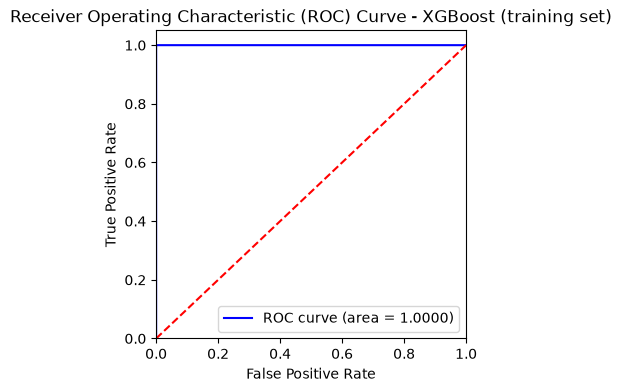

In [37]:
plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_train_xgb, y_prob_xgb))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - XGBoost (training set)')
plt.legend(loc="lower right")
plt.show()

In [38]:
roc_auc_score(y_train_xgb, y_prob_xgb)
print(f"AUC Score (XGBoost Training): {roc_auc_score(y_train_xgb, y_prob_xgb):.4f}")

AUC Score (XGBoost Training): 1.0000


#### XGBoost test set

In [39]:
y_pred_xgb_test = cls.predict(X_test)
y_prob_xgb_test = cls.predict_proba(X_test)[:, 1]

In [40]:
cm_xgb_test = confusion_matrix(y_test_xgb, y_pred_xgb_test)
cm_xgb_df_test = pd.DataFrame(cm_xgb_test, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for XGBoost (Test):")
cm_xgb_df_test

Confusion Matrix for XGBoost (Test):


,pred_neg,pred_pos
actual_neg,15606,19
actual_pos,81,294


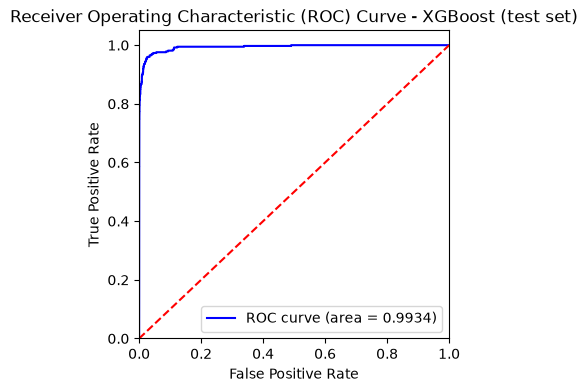

In [41]:
fpr, tpr, thresholds = roc_curve(y_test_xgb, y_prob_xgb_test)

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_test_xgb, y_prob_xgb_test))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - XGBoost (test set)')
plt.legend(loc="lower right")
plt.show()

In [42]:
roc_auc_score(y_test_xgb, y_prob_xgb_test)
print(f"AUC Score (XGBoost Test): {roc_auc_score(y_test_xgb, y_prob_xgb_test):.4f}")

AUC Score (XGBoost Test): 0.9934


#### 5-fold CV error vs. test error

In [43]:
test_error = 1 - accuracy_score(y_test_xgb, y_pred_xgb_test)
print(f"5-Fold CV Error: {cv_error:.4%}")
print(f"Test Error: {test_error:.4%}")
print(f'5-fold CV error and test error are very close, only {abs(cv_error - test_error):.4%} apart, indicating that the cross-validation model is a good approximation of the observed test misclassification error.')

5-Fold CV Error: 0.6067%
Test Error: 0.6250%
5-fold CV error and test error are very close, only 0.0183% apart, indicating that the cross-validation model is a good approximation of the observed test misclassification error.


### (f) Use SMOTE to pre-process your data

In [44]:
dict_alpha_cv = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for reg_alpha in alphas:
    cls_cv = xgb.XGBClassifier(reg_alpha=reg_alpha, random_state=42)
    pipeline = Pipeline([('smote', SMOTE(random_state=42)), ('xgb', cls_cv)])
    scores_cv = cross_val_score(pipeline, X_train, y_train_xgb, cv=cv, scoring='roc_auc')
    dict_alpha_cv[reg_alpha] = scores_cv.mean()

best_alpha_cv = max(dict_alpha_cv, key=dict_alpha_cv.get)

#### 1(f)i Train

In [45]:
cls_cv_best = xgb.XGBClassifier(reg_alpha=best_alpha_cv, random_state=42)
pipeline = Pipeline([('smote', SMOTE(random_state=42)), ('xgb', cls_cv_best)])
pipeline.fit(X_train, y_train_xgb)
y_pred_xgb_cv = pipeline.predict(X_train)
y_prob_xgb_cv = pipeline.predict_proba(X_train)[:, 1]

In [46]:
cm_xgb_cv = confusion_matrix(y_train_xgb, y_pred_xgb_cv)
cm_xgb_df_cv = pd.DataFrame(cm_xgb_cv, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for XGBoost (Training) with SMOTE:")
cm_xgb_df_cv

Confusion Matrix for XGBoost (Training) with SMOTE:


,pred_neg,pred_pos
actual_neg,59000,0
actual_pos,2,998


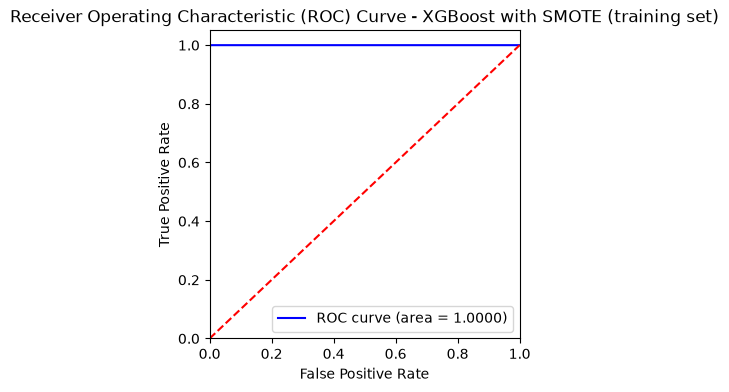

In [47]:
fpr, tpr, thresholds = roc_curve(y_train_xgb, y_prob_xgb_cv)

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_train_xgb, y_prob_xgb_cv))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - XGBoost with SMOTE (training set)')
plt.legend(loc="lower right")
plt.show()

In [48]:
roc_auc_score_xgb_cv = roc_auc_score(y_train_xgb, y_prob_xgb_cv)
print(f"AUC Score (XGBoost Training with SMOTE): {roc_auc_score_xgb_cv:.4f}")

AUC Score (XGBoost Training with SMOTE): 1.0000


#### 1(f)ii Test

In [49]:
y_pred_xgb_cv_test = pipeline.predict(X_test)
y_prob_xgb_cv_test = pipeline.predict_proba(X_test)[:, 1]

cm_xgb_cv_test = confusion_matrix(y_test_xgb, y_pred_xgb_cv_test)
cm_xgb_df_cv_test = pd.DataFrame(cm_xgb_cv_test, index=['actual_neg', 'actual_pos'], columns=['pred_neg', 'pred_pos'])
print("Confusion Matrix for XGBoost (Test) with SMOTE:")
cm_xgb_df_cv_test

Confusion Matrix for XGBoost (Test) with SMOTE:


,pred_neg,pred_pos
actual_neg,15584,41
actual_pos,70,305


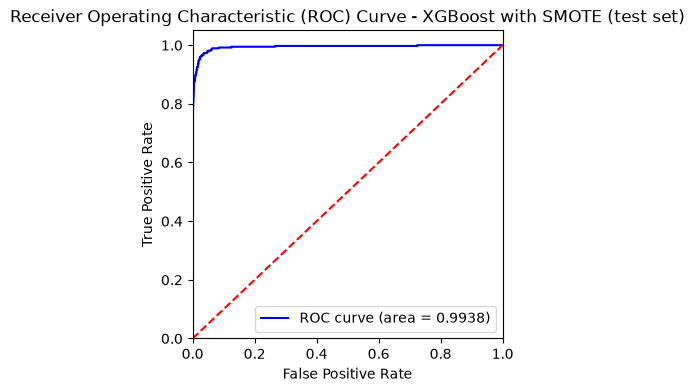

In [50]:
fpr, tpr, thresholds = roc_curve(y_test_xgb, y_prob_xgb_cv_test)

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.4f)' % roc_auc_score(y_test_xgb, y_prob_xgb_cv_test))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - XGBoost with SMOTE (test set)')
plt.legend(loc="lower right")
plt.show()

In [51]:
roc_auc_score_xgb_cv_test = roc_auc_score(y_test_xgb, y_prob_xgb_cv_test)
print(f"AUC Score (XGBoost Test with SMOTE): {roc_auc_score_xgb_cv_test:.4f}")

AUC Score (XGBoost Test with SMOTE): 0.9938


#### 5-fold CV error vs. test error

In [52]:
cv_scores_smote = cross_val_score(pipeline, X_train, y_train_xgb, cv=cv, scoring='accuracy')
cv_error_smote = 1 - cv_scores_smote.mean()
test_error_smote = 1 - accuracy_score(y_test_xgb, y_pred_xgb_cv_test)

print(f"5-Fold CV Error (SMOTE): {cv_error_smote:.4%}")
print(f"Test Error (SMOTE): {test_error_smote:.4%}")

5-Fold CV Error (SMOTE): 0.6417%
Test Error (SMOTE): 0.6938%



#### XGBoost without SMOTE vs. XGBoost with SMOTE

| Metric | Without SMOTE (1e) | With SMOTE (1f) |
|---|---:|---:|
| Training AUC | 1.0000 | 1.0000 |
| Test AUC | 0.9934 | 0.9938 |
| 5-fold CV error | 0.6067% | 0.6417% |
| Test misclassification error | 0.6250% | 0.6938% |
| Test false positives | 19 | 41 |
| Test false negatives | 81 | 70 |
| Test positive-class recall | 78.40% | 81.33% |

**Compare the uncompensated case with SMOTE case.** In 1(f), SMOTE did not meaningfully improve overall predictive performance, but it improved minority-class recall at the expense of more false positives. For APS failure detection, that tradeoff could be worthwhile if missing an actual failure is more costly than a false alarm.

## 2. ISLR 6.6.3

(a) iv (s increases -> L1 constraint relaxes -> model fits training data better -> training RSS decreases)  
(b) ii (s increases -> test RSS decreases as bias decreases -> test RSS reaches a minimum -> test RSS increases as variance increases)  
(c) iii (s increases -> flexibility increases -> variance increases)  
(d) iv (s increases -> flexibility increases -> bias decreases)  
(e) v (irreducible error is not captured by the model, so it is independent of model flexibility)  

## 3. ISLR 6.6.5

(a) 
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2+(y_2-x_{21}(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)
\right]
$$
(b)

First, we minimize the Ridge penalty:

$$
\begin{aligned}
\lambda(\beta_1^2+\beta_2^2)
&=\lambda[\beta_1^2+(s-\beta_1)^2]\\
&=\lambda(2\beta_1^2-2s\beta_1+s^2)
\end{aligned}
$$

Taking the derivative with respect to $\beta_1$ and setting it equal to zero:

$$
\begin{aligned}
4\lambda\beta_1-2\lambda s&=0\\
\beta_1&=\frac{s}{2}
\end{aligned}
$$

Since $\beta_2=s-\beta_1$, we also have $\beta_2=\frac{s}{2}$.

Therefore, for $\lambda>0$, the Ridge penalty is minimized when:

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}
$$

(c) 
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|)
\right]
$$

(d)

If $s>0$ and both coefficients are nonnegative, the Lasso penalty becomes:

$$
\lambda(|\beta_1|+|\beta_2|)=\lambda(\beta_1+\beta_2)=\lambda s
$$

Therefore, any nonnegative pair of coefficients satisfying $\beta_1+\beta_2=s$ produces the same RSS and the same Lasso penalty.

For example, $(\beta_1,\beta_2)=(s,0)$ and $(s/2,s/2)$ produce identical objective values.

Similarly, if $s<0$, any pair of nonpositive coefficients summing to $s$ produces the same objective value.

Thus, when the optimal sum $s\neq 0$, the Lasso coefficient estimates are **not unique**. Any pair satisfying $\beta_1+\beta_2=s$ with both coefficients having the same sign as $s$ (or one being zero) is an optimal solution.

If the optimal sum is $s=0$, the unique solution is $\beta_1=\beta_2=0$.


## 4. ISLR 8.4.5

**Majority voting**:
* If P(Red|X) > .5 => Red
* If P(Red|X) < .5 => Green
* 6 of 10 classification trees predict Red because P(Red|X) > .5.
* Thus, based on majority voting, the final classification is **Red**.

**Average probability**:  
P(Red|X) = (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10
= .45

Since .45 < .5, the final classification is **Green**.

## 5. ISLR 9.7.3

(a)

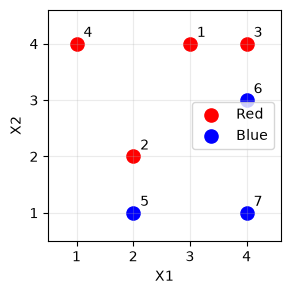

In [53]:
import matplotlib.pyplot as plt
red = [(3,4), (2,2), (4,4), (1,4)]
blue = [(2,1), (4,3), (4,1)]
plt.figure(figsize=(3,3)); plt.scatter(*zip(*red), color='red', label='Red', s=90); plt.scatter(*zip(*blue), color='blue', label='Blue', s=90)
for i, (x,y) in enumerate(red + blue, 1):
    plt.annotate(str(i), (x,y), xytext=(5,5), textcoords='offset points')
plt.xlabel('X1'); plt.ylabel('X2'); plt.xticks([1,2,3,4]); plt.yticks([1,2,3,4]); plt.xlim(0.5,4.6); plt.ylim(0.5,4.6); plt.grid(alpha=0.25); plt.legend()
plt.show()

#### (b) 
$$
1 - 2X_1 + 2X_2 = 0
$$

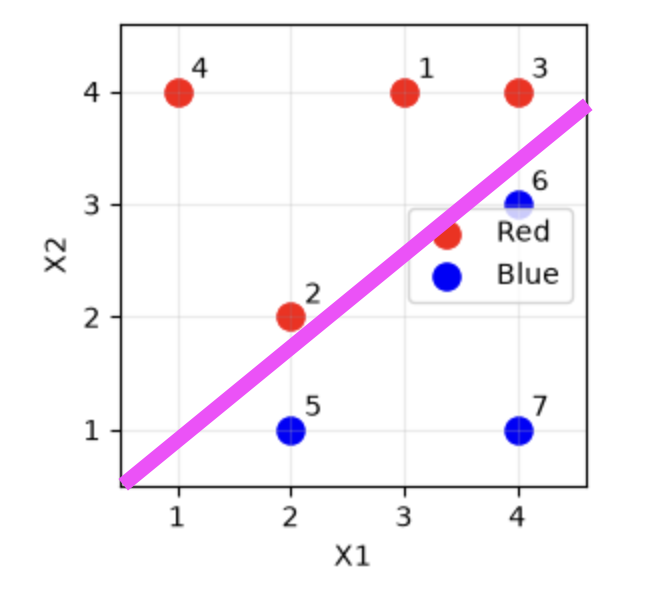

#### (c)

If the hyperplane is 1 - 2X_1 + 2X_2 = 0, then the classification rule is:  

1 - 2X_1 + 2X_2 > 0 => Red  
1 - 2X_1 + 2X_2 < 0 => Blue  

Thus the coefficients are: beta_0 = 1, beta_1 = -2, beta_2 = 2  

#### (d)

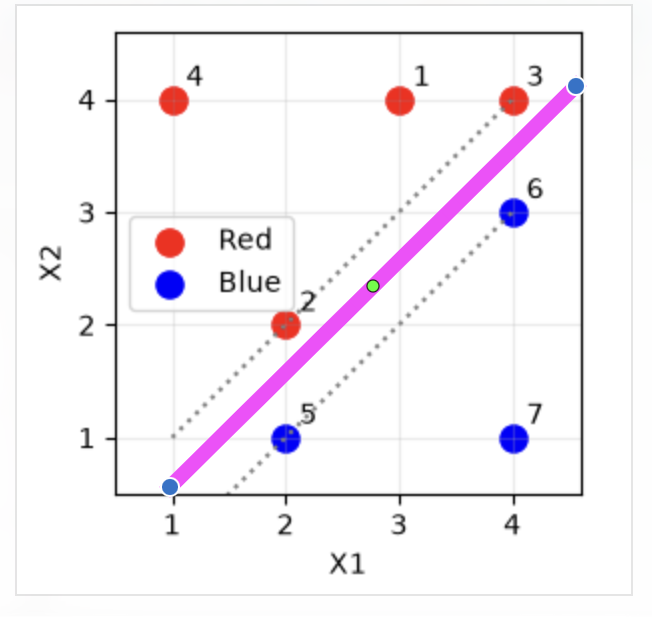

#### (e)
Support vectors are: observation 2, 3, 6 and 5

#### (f)
If observation 7 were to slightly move, it would not affect the maximal margin hyperplane because it is not an observation that defines the hyperplane (i.e., it is not a support vector and therefore does not define the hyperplane).

#### (g)
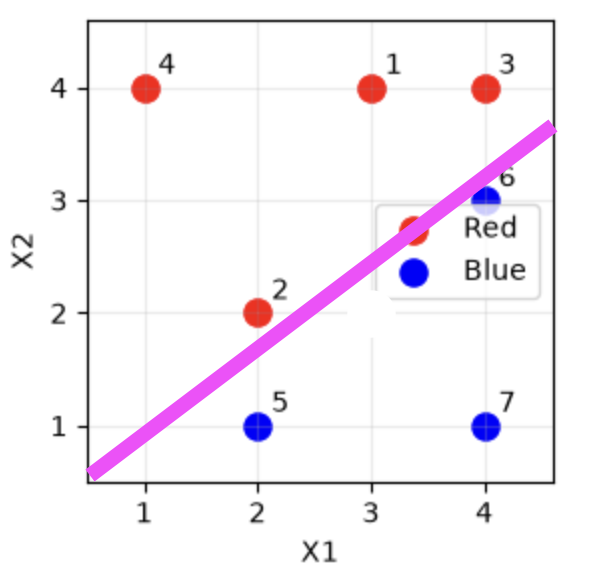  
The equation for this hyperplane is approximately:
$$
X_2 = .8X_1 - .4
$$

#### (h)
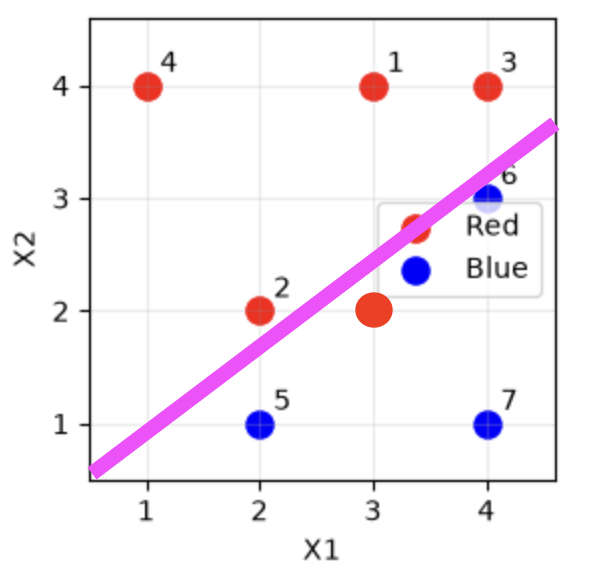